In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Find all review CSV files
review_files = sorted(
    Path("../data/raw").glob("reviews_*.csv")
)

print("Review files found:", len(review_files))

# Load and combine all review files
reviews_list = []

for file in review_files:
    temp_df = pd.read_csv(file, low_memory=False)
    reviews_list.append(temp_df)

    print(f"{file.name}: {len(temp_df):,} rows")

if not reviews_list:
    raise FileNotFoundError("No review CSV files found!")

reviews_df = pd.concat(
    reviews_list,
    ignore_index=True
)

print("\nTotal review records:", len(reviews_df))
print("Total columns:", reviews_df.shape[1])

display(reviews_df.head())


Review files found: 5
reviews_0-250.csv: 602,130 rows
reviews_1250-end.csv: 49,977 rows
reviews_250-500.csv: 206,725 rows
reviews_500-750.csv: 116,262 rows
reviews_750-1250.csv: 119,317 rows

Total review records: 1094411
Total columns: 19


,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,1741593524,5,1.0,1.0,2,0,2,2023-02-01,I use this with the Nudestix “Citrus Clean Bal...,Taught me how to double cleanse!,NaN,brown,dry,black,P504322,Gentle Hydra-Gel Face Cleanser,NUDESTIX,19.0
1,1,31423088263,1,0.0,NaN,0,0,0,2023-03-21,I bought this lip mask after reading the revie...,Disappointed,NaN,NaN,NaN,NaN,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
2,2,5061282401,5,1.0,NaN,0,0,0,2023-03-21,My review title says it all! I get so excited ...,New Favorite Routine,light,brown,dry,blonde,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
3,3,6083038851,5,1.0,NaN,0,0,0,2023-03-20,I’ve always loved this formula for a long time...,Can't go wrong with any of them,NaN,brown,combination,black,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
4,4,47056667835,5,1.0,NaN,0,0,0,2023-03-20,"If you have dry cracked lips, this is a must h...",A must have !!!,light,hazel,combination,NaN,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0


In [2]:

# User-Product Interaction Overview

print("USER INTERACTION ANALYSIS")
print("-" * 40)

print("Total review records:", len(reviews_df))

print(
    "Unique users:",
    reviews_df["author_id"].nunique()
)

print(
    "Unique reviewed products:",
    reviews_df["product_id"].nunique()
)

print("\nReview columns:")
print(reviews_df.columns.tolist())

print("\nMissing values in important columns:")
print(
    reviews_df[
        ["author_id", "product_id", "rating"]
    ].isnull().sum()
)


USER INTERACTION ANALYSIS
----------------------------------------
Total review records: 1094411
Unique users: 503216
Unique reviewed products: 2351

Review columns:
['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

Missing values in important columns:
author_id     0
product_id    0
rating        0
dtype: int64


REVIEWS PER USER
----------------------------------------
count    503216.000000
mean          2.174833
std           3.414628
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         292.000000
dtype: float64

Users with at least 2 reviews: 210468
Users with at least 5 reviews: 40880
Users with at least 10 reviews: 9387


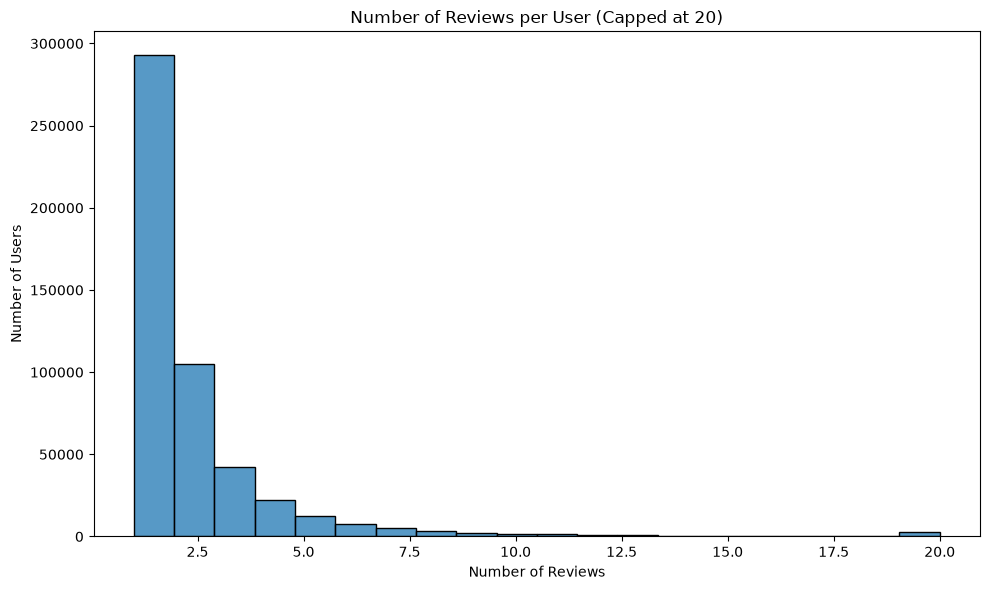

In [3]:

# Reviews per User Analysis

reviews_per_user = reviews_df.groupby(
    "author_id"
).size()

print("REVIEWS PER USER")
print("-" * 40)

print(reviews_per_user.describe())

print("\nUsers with at least 2 reviews:",
      (reviews_per_user >= 2).sum())

print("Users with at least 5 reviews:",
      (reviews_per_user >= 5).sum())

print("Users with at least 10 reviews:",
      (reviews_per_user >= 10).sum())

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    reviews_per_user.clip(upper=20),
    bins=20
)

plt.title("Number of Reviews per User (Capped at 20)")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()


In [4]:

# Product and Review Matching Analysis

products_df = pd.read_csv(
    "../data/processed/product_info_cleaned.csv",
    low_memory=False
)

product_ids = set(products_df["product_id"])
review_product_ids = set(reviews_df["product_id"])

matched_ids = product_ids.intersection(review_product_ids)

print("PRODUCT MATCHING ANALYSIS")
print("-" * 40)

print("Total products:", len(product_ids))
print("Reviewed products:", len(review_product_ids))
print("Matched products:", len(matched_ids))

print("Reviews with matching products:",
      reviews_df["product_id"].isin(product_ids).sum())

print("Reviews without matching products:",
      (~reviews_df["product_id"].isin(product_ids)).sum())


PRODUCT MATCHING ANALYSIS
----------------------------------------
Total products: 8494
Reviewed products: 2351
Matched products: 2351
Reviews with matching products: 1094411
Reviews without matching products: 0


In [5]:

# Positive User Interaction Analysis

positive_reviews = reviews_df[
    (reviews_df["rating"] >= 4) &
    (reviews_df["product_id"].isin(product_ids))
].copy()

print("POSITIVE INTERACTION ANALYSIS")
print("-" * 40)

print("Total positive interactions:", len(positive_reviews))

print("Unique positive users:",
      positive_reviews["author_id"].nunique())

print("Unique positively rated products:",
      positive_reviews["product_id"].nunique())

print("\nPositive rating distribution:")
print(positive_reviews["rating"].value_counts().sort_index())


POSITIVE INTERACTION ANALYSIS
----------------------------------------
Total positive interactions: 898340
Unique positive users: 430165
Unique positively rated products: 2343

Positive rating distribution:
rating
4    199389
5    698951
Name: count, dtype: int64


In [6]:

# Count unique positively rated products per user

positive_product_counts = (
    positive_reviews
    .groupby("author_id")["product_id"]
    .nunique()
)

print("POSITIVE PRODUCTS PER USER")
print("-" * 40)

print(positive_product_counts.describe())

print("\nUsers with at least 2 positive products:",
      (positive_product_counts >= 2).sum())

print("Users with at least 5 positive products:",
      (positive_product_counts >= 5).sum())

print("Users with at least 10 positive products:",
      (positive_product_counts >= 10).sum())


POSITIVE PRODUCTS PER USER
----------------------------------------
count    430165.000000
mean          2.077398
std           3.307804
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         253.000000
Name: product_id, dtype: float64

Users with at least 2 positive products: 172439
Users with at least 5 positive products: 30078
Users with at least 10 positive products: 6859


In [7]:

# User-Product Duplicate Analysis

duplicate_interactions = reviews_df.duplicated(
    subset=["author_id", "product_id"]
).sum()

print("DUPLICATE INTERACTION ANALYSIS")
print("-" * 40)

print("Duplicate user-product interactions:",
      duplicate_interactions)

print("\nUnique user-product pairs:",
      reviews_df[
          ["author_id", "product_id"]
      ].drop_duplicates().shape[0])


DUPLICATE INTERACTION ANALYSIS
----------------------------------------
Duplicate user-product interactions: 5525

Unique user-product pairs: 1088886


USER RATING DISTRIBUTION
----------------------------------------
rating
1     61223
2     53032
3     81816
4    199389
5    698951
Name: count, dtype: int64


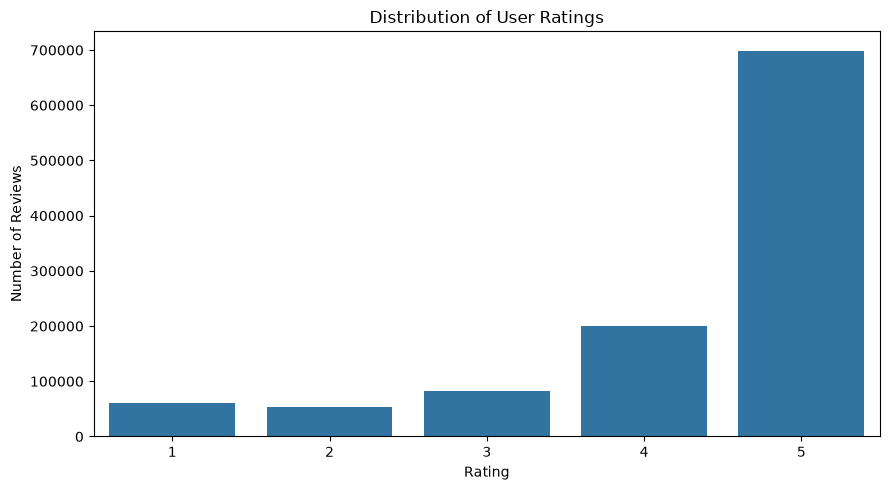

In [8]:

# User Rating Distribution

rating_counts = (
    reviews_df["rating"]
    .value_counts()
    .sort_index()
)

print("USER RATING DISTRIBUTION")
print("-" * 40)

print(rating_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of User Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


In [9]:

# Remove duplicate user-product interactions
# by calculating the average rating

interactions_clean = (
    reviews_df
    .groupby(["author_id", "product_id"], as_index=False)
    .agg(rating=("rating", "mean"))
)

print("Original interactions:", len(reviews_df))
print("Unique interactions:", len(interactions_clean))

# Define positive interactions
interactions_clean["positive"] = (
    interactions_clean["rating"] >= 4
)

print("\nPositive interactions:",
      interactions_clean["positive"].sum())

display(interactions_clean.head())


Original interactions: 1094411
Unique interactions: 1088886

Positive interactions: 893357


,author_id,product_id,rating,positive
0,10000015049,P427417,5.0,True
1,1000001620,P467115,4.0,True
2,10000049623,P422003,5.0,True
3,10000060335,P269122,5.0,True
4,10000098796,P126301,5.0,True


In [10]:

# Select users with at least 5 positive products

positive_interactions = interactions_clean[
    interactions_clean["positive"]
].copy()

user_product_counts = (
    positive_interactions
    .groupby("author_id")["product_id"]
    .nunique()
)

eligible_users = user_product_counts[
    user_product_counts >= 5
].index

eligible_interactions = positive_interactions[
    positive_interactions["author_id"].isin(eligible_users)
].copy()

print("Eligible users:", len(eligible_users))
print("Eligible positive interactions:",
      len(eligible_interactions))

print("Unique eligible products:",
      eligible_interactions["product_id"].nunique())


Eligible users: 30061
Eligible positive interactions: 280853
Unique eligible products: 2201


In [11]:

# User-based Train/Test Split

from sklearn.model_selection import train_test_split

train_parts = []
test_parts = []

for user_id, group in eligible_interactions.groupby("author_id"):

    train_user, test_user = train_test_split(
        group,
        test_size=0.2,
        random_state=42
    )

    train_parts.append(train_user)
    test_parts.append(test_user)

train_df = pd.concat(
    train_parts,
    ignore_index=True
)

test_df = pd.concat(
    test_parts,
    ignore_index=True
)

print("Training interactions:", len(train_df))
print("Testing interactions:", len(test_df))

print("\nTraining users:", train_df["author_id"].nunique())
print("Testing users:", test_df["author_id"].nunique())

print("\nTrain/Test overlap:",
    len(
        set(zip(train_df["author_id"], train_df["product_id"]))
        &
        set(zip(test_df["author_id"], test_df["product_id"]))
    )
)


Training interactions: 213982
Testing interactions: 66871

Training users: 30061
Testing users: 30061

Train/Test overlap: 0


In [12]:

# Save Train and Test Datasets

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(
    output_dir / "train_interactions.csv",
    index=False
)

test_df.to_csv(
    output_dir / "test_interactions.csv",
    index=False
)

print("Training and testing datasets saved!")
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)


Training and testing datasets saved!
Train shape: (213982, 4)
Test shape: (66871, 4)
